# Euro-Dollar Exchange Rates over Time

## Introduction

This project explores daily euro exchange rates published by the European Central Bank and compiled by Daria Chemkaeva on [Kaggle](https://www.kaggle.com/datasets/lsind18/euro-exchange-daily-rates-19992020). The dataset is updated regularly; the version used here was downloaded in November 2026 and covers January 1999 through June 2026. We focus on the euro (`€`) to US dollar (`$`) rate. Each rate shows how many US dollars one euro buys. For example, a rate of 1.20 means €1 = $1.20.

The analysis compares how the exchange rate moved during the terms of four recent US presidents: George W. Bush, Barack Obama, Donald Trump (first term) and Joe Biden.

The goal of this project is to build a reader-focused, explanatory data visualization that applies information design principles. The key principles used are:
- **Audience familiarity:** line charts, which most readers already know how to read, with years on the x-axis and plain-language labels.
- **Maximizing the data-ink ratio:** faded tick labels and light gridlines, with no chart borders, so the data lines stand out.
- **Gestalt principles:**
  - *Similarity:* color groups the presidents by party (red for Republican, blue for Democrat).
  - *Enclosure:* shaded regions mark each term in the combined chart.
  - *Proximity:* the four individual charts sit together above the combined timeline.
- **Pre-attentive attributes:** color, bold text, size and spacing draw the eye to each president's name and average before the details.


### Importing Data and Libraries

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
%matplotlib inline
import matplotlib.style as style
import numpy as np

In [2]:
exchange_rates = pd.read_csv("data/euro-daily-hist_1999_.csv")

In [3]:
exchange_rates.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7082 entries, 0 to 7081
Data columns (total 41 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Period\Unit:              7082 non-null   object 
 1   [Australian dollar ]      7082 non-null   object 
 2   [Bulgarian lev ]          6573 non-null   object 
 3   [Brazilian real ]         6814 non-null   object 
 4   [Canadian dollar ]        7082 non-null   object 
 5   [Swiss franc ]            7082 non-null   object 
 6   [Chinese yuan renminbi ]  6814 non-null   object 
 7   [Cypriot pound ]          2346 non-null   object 
 8   [Czech koruna ]           7082 non-null   object 
 9   [Danish krone ]           7082 non-null   object 
 10  [Estonian kroon ]         3130 non-null   object 
 11  [UK pound sterling ]      7082 non-null   object 
 12  [Greek drachma ]          520 non-null    object 
 13  [Hong Kong dollar ]       7082 non-null   object 
 14  [Croatia

In [4]:
print(exchange_rates.head(5))

print(exchange_rates.tail(5))

  Period\Unit: [Australian dollar ] [Bulgarian lev ] [Brazilian real ]  \
0   2026-06-04               1.6297              NaN            5.8951   
1   2026-06-03               1.6218              NaN            5.8284   
2   2026-06-02               1.6221              NaN             5.831   
3   2026-06-01               1.6234              NaN            5.8515   
4   2026-05-29               1.6238              NaN            5.8747   

  [Canadian dollar ] [Swiss franc ] [Chinese yuan renminbi ] [Cypriot pound ]  \
0             1.6176         0.9168                   7.8848              NaN   
1             1.6094         0.9167                    7.862              NaN   
2             1.6119         0.9149                   7.8778              NaN   
3             1.6106         0.9128                   7.8786              NaN   
4             1.6074         0.9111                   7.8793              NaN   

  [Czech koruna ] [Danish krone ]  ... [Romanian leu ] [Russian roub

### Data Cleaning

Before the analysis, we need to clean and standardize the data. Because we are focused on the euro-dollar rate, we rename the `[US dollar ]` column to `US_dollar`. Because we are tracking the rate over time, we also rename the `Period\Unit:` column to `Time` and convert it to a datetime type, then sort the rows from oldest to newest.

In [5]:
exchange_rates.rename(columns={'[US dollar ]': 'US_dollar',
                               'Period\\Unit:': 'Time'},
                      inplace=True)
exchange_rates['Time'] = pd.to_datetime(exchange_rates['Time'])
exchange_rates.sort_values('Time', inplace=True)
exchange_rates.reset_index(drop=True, inplace=True)

In [6]:
euro_to_dollar = exchange_rates[["Time", "US_dollar"]]

euro_to_dollar["US_dollar"].value_counts()

US_dollar
-         62
1.2276     9
1.0867     8
1.0888     8
1.1215     8
          ..
1.5660     1
1.5632     1
1.5722     1
1.5693     1
1.1595     1
Name: count, Length: 3927, dtype: int64

The `US_dollar` column contains 62 rows where the rate is recorded as `-`, meaning no rate was published that day (for example, on bank holidays). We drop these rows and convert the column to a float.

In [7]:
euro_to_dollar = euro_to_dollar.drop(euro_to_dollar[euro_to_dollar['US_dollar'] == '-'].index)
euro_to_dollar['US_dollar'] = euro_to_dollar['US_dollar'].astype(float)
euro_to_dollar['US_dollar'].info()

<class 'pandas.core.series.Series'>
Index: 7020 entries, 0 to 7081
Series name: US_dollar
Non-Null Count  Dtype  
--------------  -----  
7020 non-null   float64
dtypes: float64(1)
memory usage: 109.7 KB


## Rolling Mean

Plotting the cleaned data shows a lot of day-to-day variation in the exchange rate. Since our goal is to show long-term trends, we use the rolling mean (moving average) instead, calculated with the `pd.Series.rolling().mean()` method.

Below, we compare several common window sizes. The 30-day (monthly) window smooths out the daily noise while still keeping the important shifts visible, so we use it for the rest of the analysis.

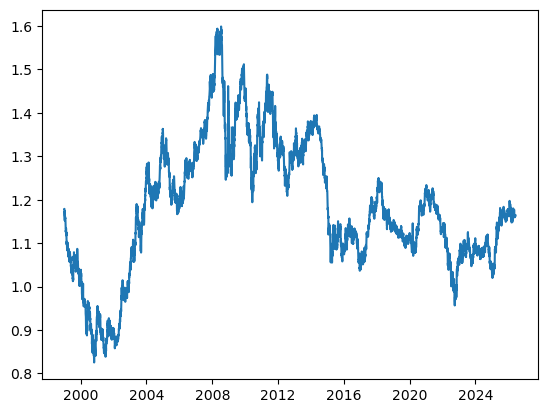

In [8]:
plt.plot(euro_to_dollar['Time'], euro_to_dollar['US_dollar'])

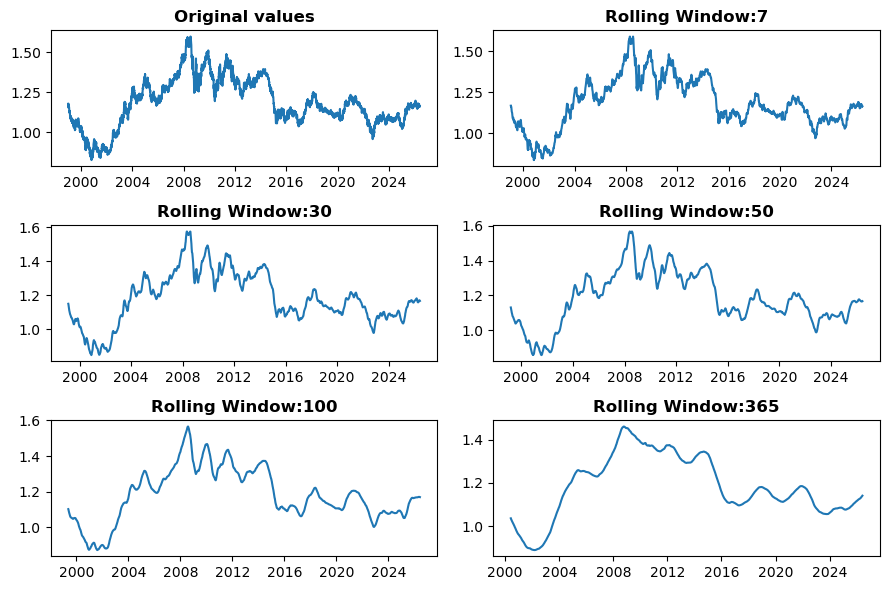

In [9]:
plt.figure(figsize=(9,6))

plt.subplot(3,2,1)
plt.plot(euro_to_dollar['Time'], euro_to_dollar['US_dollar'])
plt.title('Original values', weight='bold')

for i, rolling_mean in zip([2, 3, 4, 5, 6],
                           [7, 30, 50, 100, 365]):
    plt.subplot(3,2,i)
    plt.plot(euro_to_dollar['Time'],
             euro_to_dollar['US_dollar'].rolling(rolling_mean).mean())
    plt.title('Rolling Window:' + str(rolling_mean), weight='bold')
    
plt.tight_layout() # Auto-adjusts the padding between subplots
plt.show()

In [10]:
euro_to_dollar['rolling_mean'] = euro_to_dollar['US_dollar'].rolling(30).mean()
euro_to_dollar

,Time,US_dollar,rolling_mean
0,1999-01-04,1.1789,NaN
1,1999-01-05,1.1790,NaN
2,1999-01-06,1.1743,NaN
3,1999-01-07,1.1632,NaN
4,1999-01-08,1.1659,NaN
...,...,...,...
7077,2026-05-29,1.1644,1.169213
7078,2026-06-01,1.1646,1.168710
7079,2026-06-02,1.1649,1.168340
7080,2026-06-03,1.1614,1.167830


## Euro-Dollar Exchange Rates under US Presidential Administrations

The `euro_to_dollar` dataframe covers 1999 to 2026, which spans four complete US presidential administrations: George W. Bush (2001–2009), Barack Obama (2009–2017), Donald Trump's first term (2017–2021) and Joe Biden (2021–2025). Trump's second term, which began in 2025, is still in progress and is left out. To keep things simple, each term is approximated by calendar year.

In [11]:
us_pres = euro_to_dollar.copy(
                   )[(euro_to_dollar['Time'].dt.year >= 2001) & (euro_to_dollar['Time'].dt.year < 2025)]
bush = us_pres.copy(
    )[us_pres['Time'].dt.year < 2009]
obama = us_pres.copy(
    )[(us_pres['Time'].dt.year >= 2009) & (us_pres['Time'].dt.year < 2017)]
trump = us_pres.copy(
    )[(us_pres['Time'].dt.year >= 2017) & (us_pres['Time'].dt.year < 2021)]
biden = us_pres.copy(
    )[(us_pres['Time'].dt.year >= 2021) & (us_pres['Time'].dt.year < 2025)]

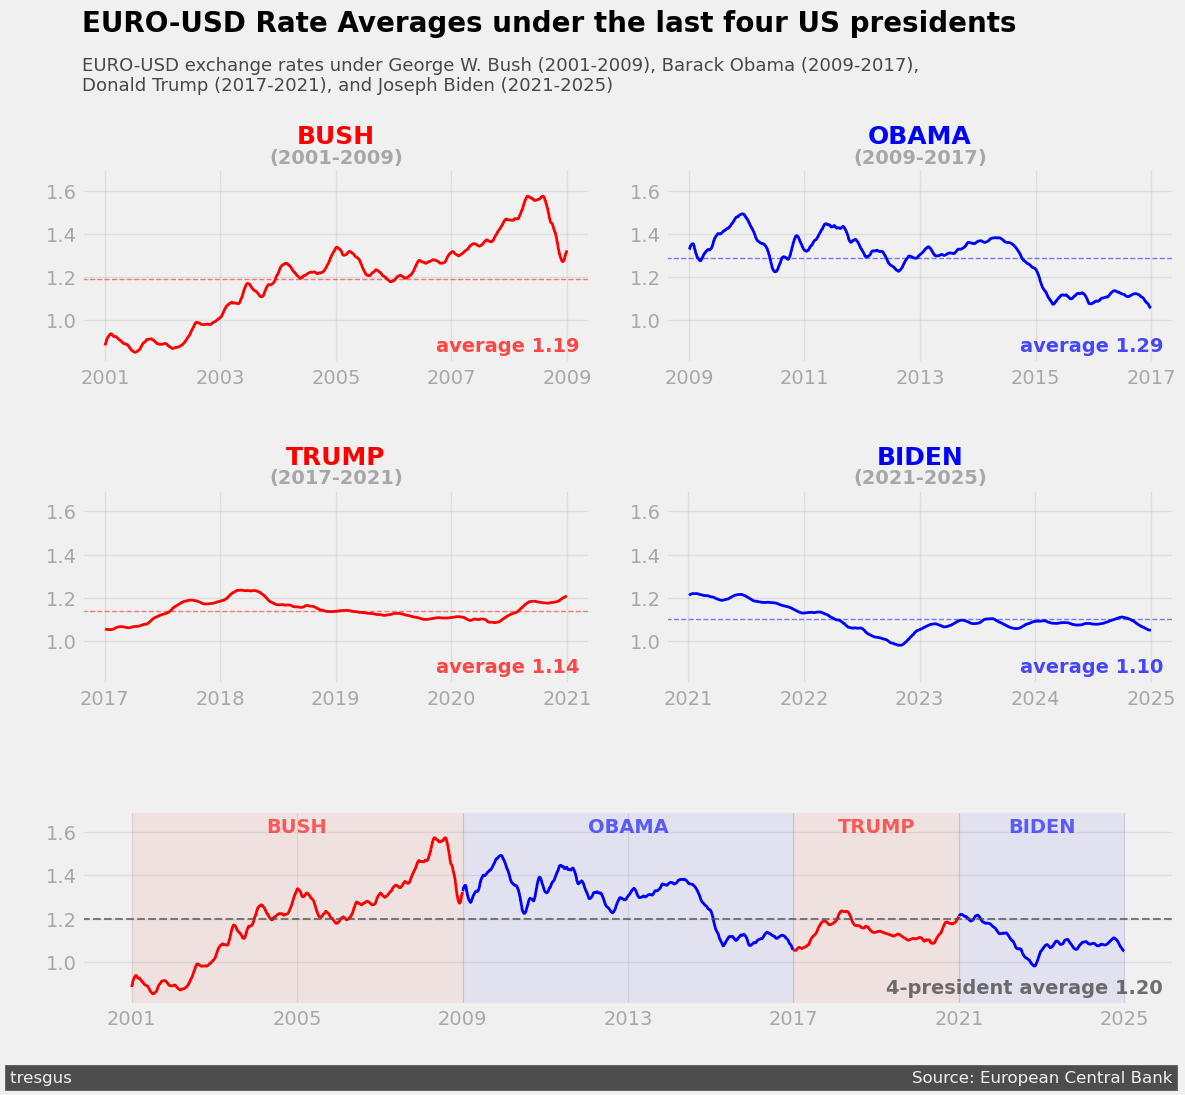

In [12]:
style.use("fivethirtyeight")

# Plot parameters for each president
presidents = [
    # (df, name, years, color, xticks, xticklabels)
    (bush,  'BUSH',  '(2001-2009)', 'red',
     [11323, 12053, 12784, 13514, 14245], ['2001', '2003', '2005', '2007', '2009']),
    (obama, 'OBAMA', '(2009-2017)', 'blue',
     [14245, 14975, 15706, 16436, 17167], ['2009', '2011', '2013', '2015', '2017']),
    (trump, 'TRUMP', '(2017-2021)', 'red',
     [17167, 17532, 17897, 18262, 18628], ['2017', '2018', '2019', '2020', '2021']),
    (biden, 'BIDEN', '(2021-2025)', 'blue',
     [18628, 18993, 19358, 19723, 20089], ['2021', '2022', '2023', '2024', '2025']),
]

# Subplot layout: four small charts on top, one combined chart below
fig = plt.figure(figsize=(12, 11), dpi=100)
ax1 = plt.subplot(3,2,1)
ax2 = plt.subplot(3,2,2)
ax3 = plt.subplot(3,2,3)
ax4 = plt.subplot(3,2,4)
ax5 = plt.subplot(3,1,3)
axes = [ax1, ax2, ax3, ax4, ax5]

# Shared y-axis settings
for ax in axes:
    ax.set_ylim(0.8, 1.7)
    ax.set_yticks([1.0, 1.2, 1.4, 1.6])
    ax.set_yticklabels(['1.0', '1.2','1.4', '1.6'],
                   alpha=0.3)
    ax.grid(alpha=0.5)    

# Top four subplots: one per president
for ax, (df, name, years, color, ticks, labels) in zip(axes[:4], presidents):
    average = df['rolling_mean'].mean()
    ax.plot(df['Time'], df['rolling_mean'], color=color, linewidth=2)
    ax.axhline(average, color=color, linestyle='--', linewidth=1, alpha=0.5)
    ax.text(0.98, 0.06, f'average {average:.2f}', transform=ax.transAxes,
            ha='right', color=color, alpha=0.7, weight='bold')
    ax.set_xticks(ticks)
    ax.set_xticklabels(labels, alpha=0.3)
    ax.text(0.5, 1.13, name, transform=ax.transAxes, ha='center',
            fontsize=18, weight='bold', color=color)
    ax.text(0.5, 1.03, years, transform=ax.transAxes, ha='center',
            weight='bold', alpha=0.3)

### Ax5: Bush-Obama-Trump-Biden
for df, name, years, color, ticks, labels in presidents:
    ax5.plot(df['Time'], df['rolling_mean'], color=color, linewidth=2)
    ax5.axvspan(ticks[0], ticks[-1], color=color, alpha=0.06)
    ax5.text((ticks[0] + ticks[-1]) / 2, 1.6, name, ha='center',
             weight='bold', color=color, alpha=0.6)
ax5.set_xticks([11323, 12784, 14245, 15706, 17167, 18628, 20089])
ax5.set_xticklabels(['2001', '2005', '2009', '2013', '2017', '2021', '2025'], alpha=0.3)

### One average line across all four presidents
overall_average = pd.concat([bush, obama, trump, biden])['rolling_mean'].mean()
ax5.axhline(overall_average, color='#4d4d4d', linestyle='--', linewidth=1.5, alpha=0.7)
ax5.text(0.99, 0.06, f'4-president average {overall_average:.2f}', transform=ax5.transAxes,
         ha='right', color='#4d4d4d', alpha=0.8, weight='bold')

### Spacing between the charts
plt.subplots_adjust(left=0.06, right=0.97, top=0.84, bottom=0.08,
                    hspace=0.65, wspace=0.15)

### Adding a title and a subtitle
fig.text(0.06, 0.965, 'EURO-USD Rate Averages under the last four US presidents',
         fontsize=20, weight='bold')
fig.text(0.06, 0.925, 'EURO-USD exchange rates under George W. Bush (2001-2009), Barack Obama (2009-2017),\n'
         'Donald Trump (2017-2021), and Joseph Biden (2021-2025)',
         fontsize=13, alpha=0.7, va='center')

### Adding a signature
fig.text(0, 0.01, 'tresgus' + ' '*160 + 'Source: European Central Bank',
         color='#f0f0f0', backgroundcolor='#4d4d4d', size=12)

plt.show()

## Conclusion

The euro was **strongest against the dollar under Obama**, averaging **1.29 USD per euro**. It was **weakest under Biden**, averaging **1.10**. Across all four presidencies combined, the rate averaged **1.20**.

| President | Years | Average rate | Pattern |
|---|---|---|---|
| Bush | 2001–2009 | 1.19 | Steady climb from about 0.85 to an all-time high near 1.58 in 2008, then a sharp drop |
| Obama | 2009–2017 | **1.29** | Stayed high (1.25–1.50) for most of the term, then fell steeply from 2014 to about 1.05 |
| Trump | 2017–2021 | 1.14 | The most stable period, staying between about 1.05 and 1.25 |
| Biden | 2021–2025 | 1.10 | Started near 1.22, dropped below parity (1.00) in late 2022, then recovered to about 1.10 |

### Key takeaways

- **The biggest moves line up with major global events, not with changes in president.** The euro peaked just before the 2008 financial crisis and fell sharply when it hit. The 2014–2015 drop matches the European Central Bank's quantitative easing program. The 2022 fall below parity matches the start of the war in Ukraine, Europe's energy crisis and aggressive Federal Reserve rate hikes in a post-covid world.
- **The euro has trended weaker over the last decade.** Bush (1.19) roughly matched the 1.20 overall average and Obama (1.29) was well above it, while Trump (1.14) and Biden (1.10) were both below it. The euro has not returned to its 2008 peak.
- **Political party shows no clear pattern.** One Republican (Bush) and one Democrat (Obama) presided over the strongest-euro years, and the other two did not.